<a href="https://colab.research.google.com/github/yohannes-wegayehu/house-price-prediction/blob/main/house_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib
import os




In [ ]:
# Create a directory to store the saved model files
os.makedirs('saved_models', exist_ok=True)

In [2]:
# Load the California Housing dataset as a pandas DataFrame
california = fetch_california_housing(as_frame=True)
df = california.frame


In [5]:

# Display the first 5 rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [6]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)



Dataset Shape: (20640, 9)


In [7]:
# Check for missing values in each column
print("\n--- Missing Values ---")
print(df.isnull().sum())




--- Missing Values ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [8]:
# View statistical summary (mean, min, max, standard deviation, etc.)
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


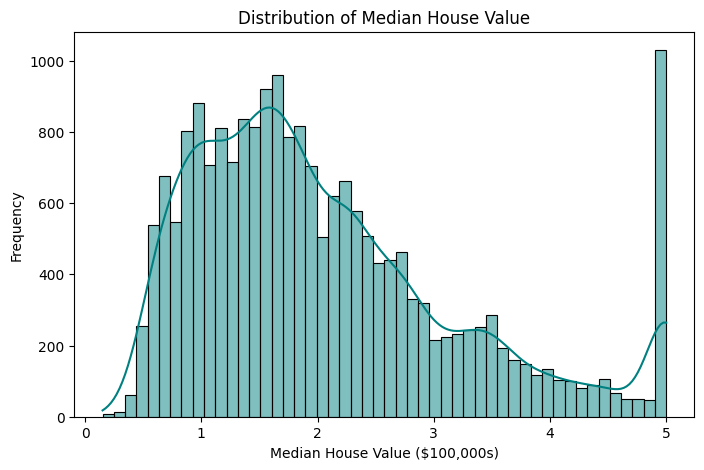

In [12]:
# Plot the distribution of median house values
plt.figure(figsize=(8, 5))
sns.histplot(df['MedHouseVal'], bins=50, kde=True, color='teal')
plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value ($100,000s)')
plt.ylabel('Frequency')
plt.show()

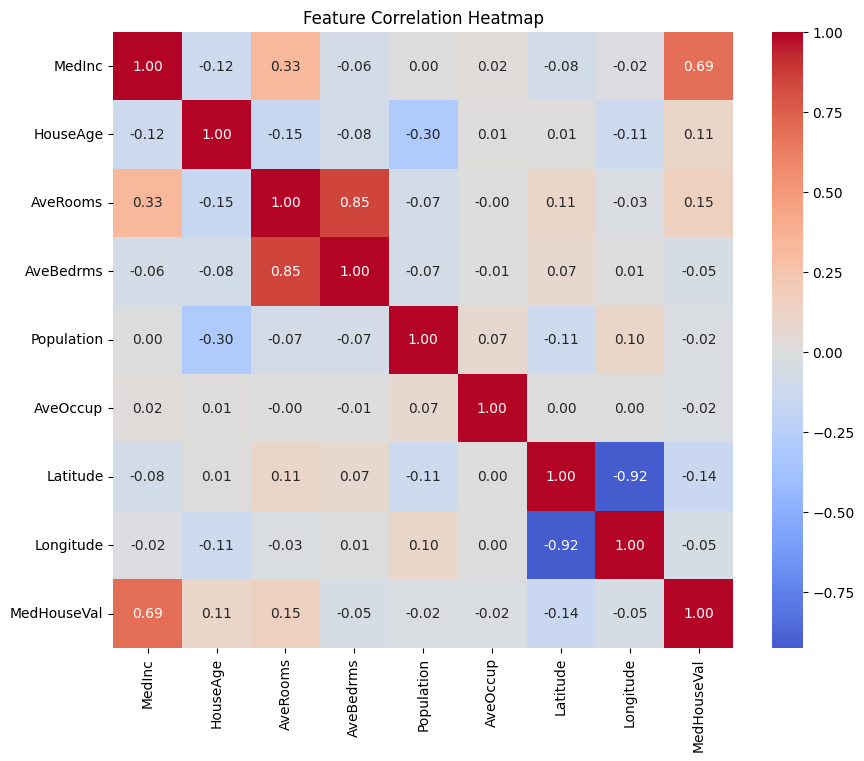

In [13]:
# Compute the correlation matrix
corr_matrix = df.corr()

# Plot the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature Correlation Heatmap')
plt.show()

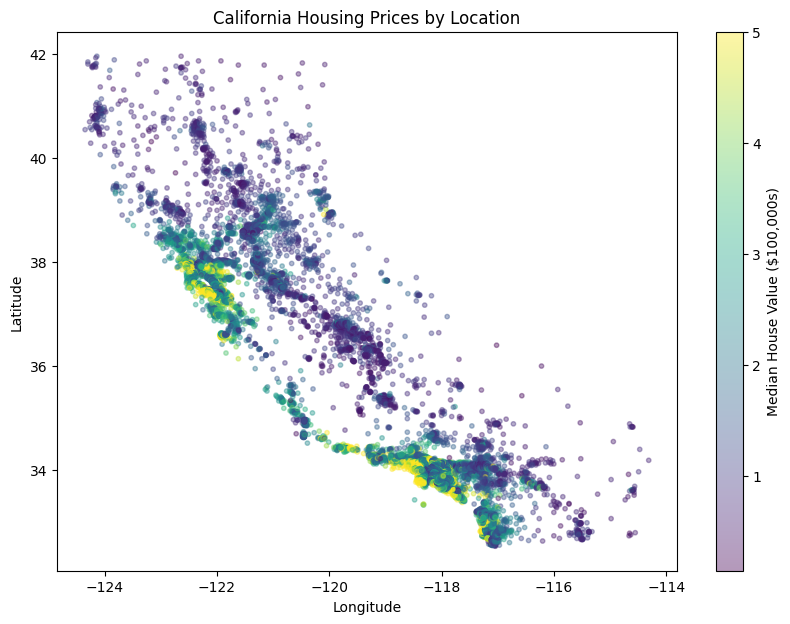

In [14]:
# Plot house locations colored by median house value
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df['Longitude'],
    df['Latitude'],
    c=df['MedHouseVal'],
    cmap='viridis',
    alpha=0.4,
    s=10
)
plt.colorbar(scatter, label='Median House Value ($100,000s)')
plt.title('California Housing Prices by Location')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [15]:
# Create a copy of the dataframe to keep the original data safe
df_fe = df.copy()

# 1. Ratio of bedrooms to total rooms
df_fe['BedroomsPerRoom'] = df_fe['AveBedrms'] / df_fe['AveRooms']

# 2. Average rooms per person in a household
df_fe['RoomsPerPerson'] = df_fe['AveRooms'] / df_fe['AveOccup']

# 3. Median income adjusted per household member
df_fe['IncomePerPerson'] = df_fe['MedInc'] / df_fe['AveOccup']

# Check correlation of all features (including new ones) with the target
new_corr = df_fe.corr()['MedHouseVal'].sort_values(ascending=False)
print(new_corr)

MedHouseVal        1.000000
IncomePerPerson    0.745628
MedInc             0.688075
RoomsPerPerson     0.209482
AveRooms           0.151948
HouseAge           0.105623
AveOccup          -0.023737
Population        -0.024650
Longitude         -0.045967
AveBedrms         -0.046701
Latitude          -0.144160
BedroomsPerRoom   -0.255624
Name: MedHouseVal, dtype: float64


In [20]:
# 1. Separate features (X) and target variable (y)
X = df_fe.drop('MedHouseVal', axis=1)
y = df_fe['MedHouseVal']

# 2. Split the data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Initialize the StandardScaler
scaler = StandardScaler()

# 4. Fit on training data and transform both training and test data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Verify the shapes of the resulting datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (16512, 11)
X_test shape: (4128, 11)


In [30]:
# 1. Initialize the three models
lr_model = LinearRegression()
dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

# 2. Train (fit) each model on the training data
lr_model.fit(X_train_scaled, y_train)
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# 3. Generate predictions on the test set
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print("All three models trained and predictions generated successfully!")



All three models trained and predictions generated successfully!


In [31]:
# Save each trained model and the scaler to disk
joblib.dump(lr_model, 'saved_models/linear_regression.pkl')
joblib.dump(dt_model, 'saved_models/decision_tree.pkl')
joblib.dump(rf_model, 'saved_models/random_forest.pkl')
joblib.dump(scaler, 'saved_models/scaler.pkl')

print("Models and scaler saved successfully in the 'saved_models/' folder!")

Models and scaler saved successfully in the 'saved_models/' folder!


In [33]:

# Define a helper function to calculate MAE, RMSE, and R2 for any model
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return {
        'Model': model_name,
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'R2 Score': round(r2, 4)
    }

# Evaluate each model and store the results in a list
results = [
    evaluate_model(y_test, y_pred_lr, 'Linear Regression'),
    evaluate_model(y_test, y_pred_dt, 'Decision Tree'),
    evaluate_model(y_test, y_pred_rf, 'Random Forest')
]

# Convert the results list into a DataFrame for clean comparison
results_df = pd.DataFrame(results)
results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.4738,0.6621,0.6654
1,Decision Tree,0.4258,0.6827,0.6443
2,Random Forest,0.3061,0.4804,0.8239


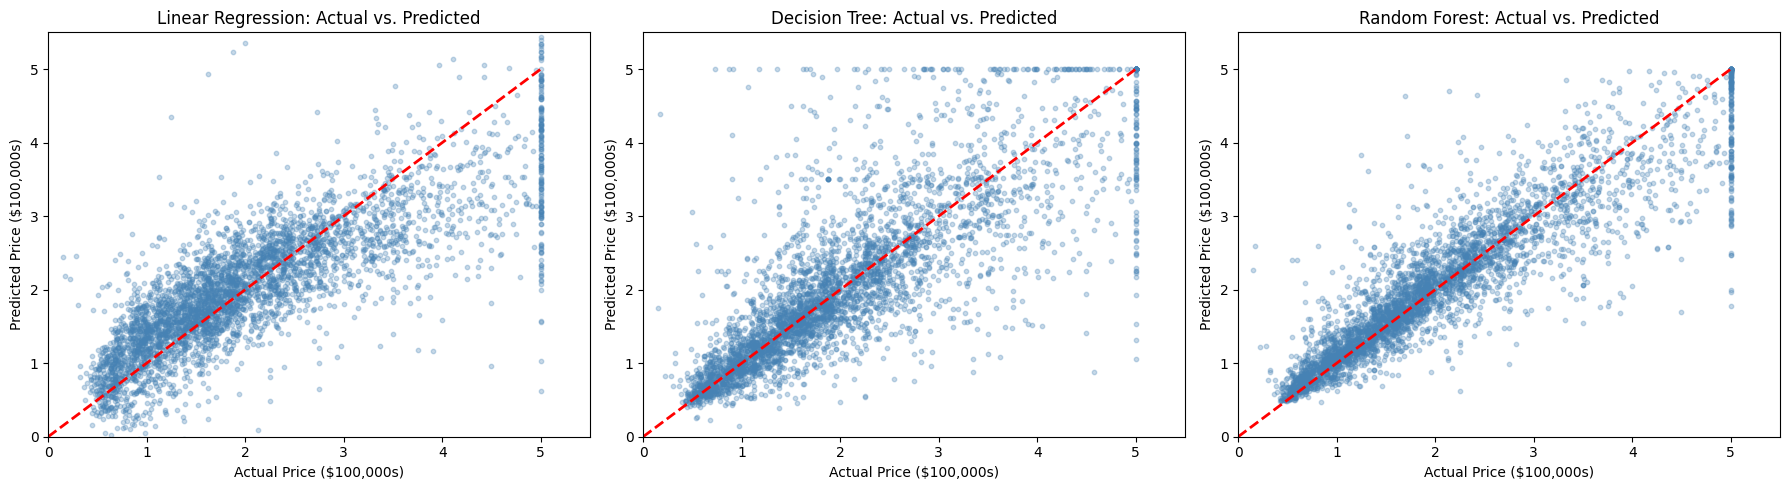

In [34]:
# Store model names and their predictions in a list of tuples
models_preds = [
    ('Linear Regression', y_pred_lr),
    ('Decision Tree', y_pred_dt),
    ('Random Forest', y_pred_rf)
]

# Create a 1-row, 3-column grid of subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loop through each model and plot Actual vs. Predicted prices
for ax, (name, y_pred) in zip(axes, models_preds):
    ax.scatter(y_test, y_pred, alpha=0.3, s=10, color='steelblue')
    ax.plot([0, 5], [0, 5], color='red', linestyle='--', linewidth=2)
    ax.set_title(f'{name}: Actual vs. Predicted')
    ax.set_xlabel('Actual Price ($100,000s)')
    ax.set_ylabel('Predicted Price ($100,000s)')
    ax.set_xlim(0, 5.5)
    ax.set_ylim(0, 5.5)

# Adjust spacing so titles and labels do not overlap
plt.tight_layout()
plt.show()

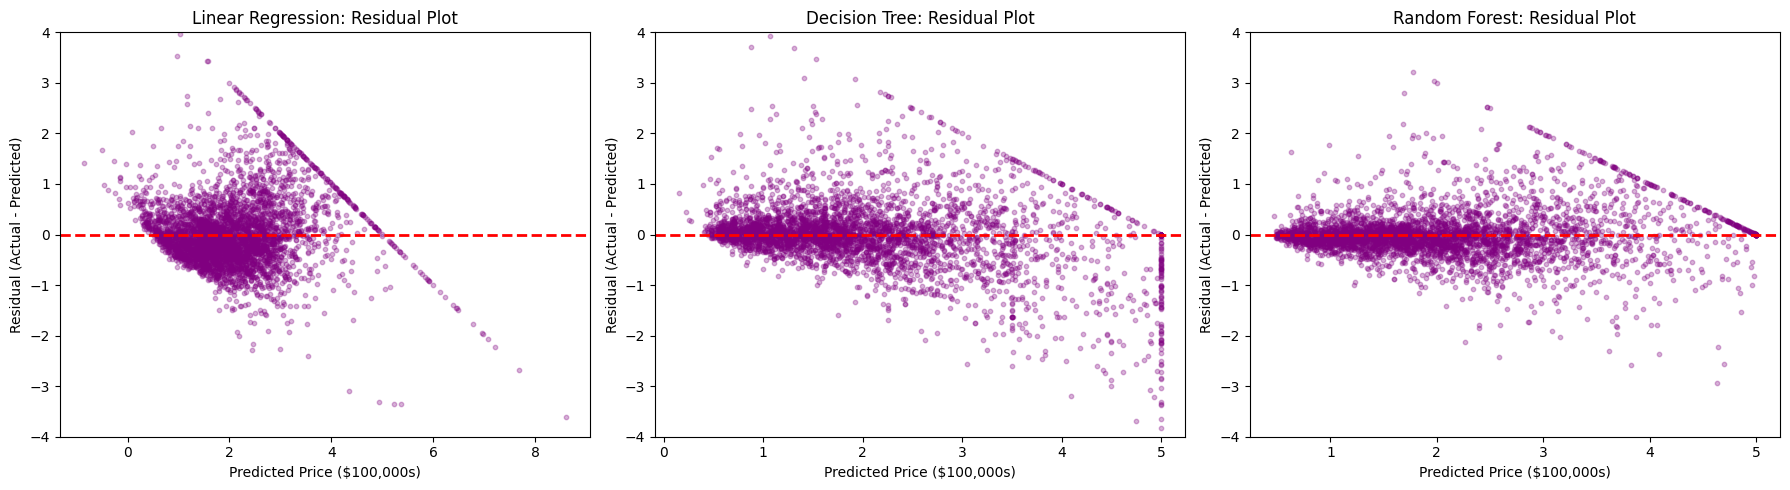

In [35]:
# Create a 1-row, 3-column grid for residual plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Loop through each model and plot its prediction errors (residuals)
for ax, (name, y_pred) in zip(axes, models_preds):
    residuals = y_test - y_pred
    ax.scatter(y_pred, residuals, alpha=0.3, s=10, color='purple')
    ax.axhline(y=0, color='red', linestyle='--', linewidth=2)
    ax.set_title(f'{name}: Residual Plot')
    ax.set_xlabel('Predicted Price ($100,000s)')
    ax.set_ylabel('Residual (Actual - Predicted)')
    ax.set_ylim(-4, 4)

plt.tight_layout()
plt.show()

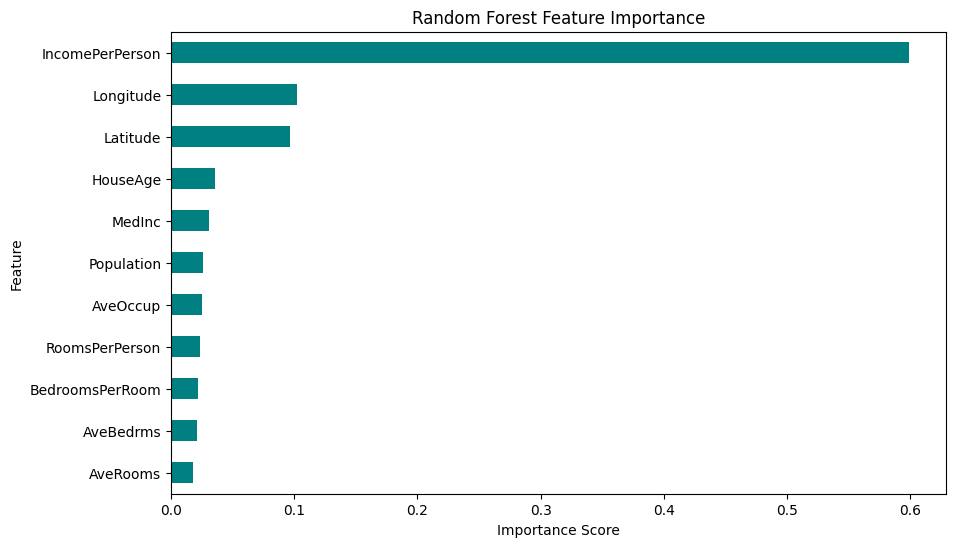

In [36]:
# Extract feature importance scores from the trained Random Forest model
importances = pd.Series(rf_model.feature_importances_, index=X.columns)

# Sort features from lowest to highest importance for horizontal bar plotting
importances = importances.sort_values(ascending=True)

# Plot the feature importances
plt.figure(figsize=(10, 6))
importances.plot(kind='barh', color='teal')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.show()